In [1]:

import os
import subprocess
from pathlib import Path

DATASET_URL = (
    "https://github.com/"
    "ahs695/Indian-Road-Damage-Infrastructure-Dataset.git"
)
DATASET_DIR = Path("/content/road_surface_dataset")

if not DATASET_DIR.exists():
    result = subprocess.run(
        [
            "git", "clone", "--depth", "1",
            DATASET_URL, str(DATASET_DIR)
        ],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "Dataset download failed.\n"
            + result.stderr[-3000:]
        )

print("Dataset downloaded successfully!")
print("Dataset path:", DATASET_DIR)

for path in sorted(DATASET_DIR.iterdir()):
    print(path.name, "->", "Folder" if path.is_dir() else "File")

print("\nImage folders:")
image_root = DATASET_DIR / "images"

if image_root.exists():
    for folder in sorted(image_root.iterdir()):
        if folder.is_dir():
            count = sum(
                1 for p in folder.rglob("*")
                if p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".webp"
                }
            )
            print(f"{folder.name}: {count} images")
else:
    print("Expected images/ folder not found.")


Dataset downloaded successfully!
Dataset path: /content/road_surface_dataset
.git -> Folder
LICENSE -> File
README.md -> File
annotations -> Folder
docs -> Folder
images -> Folder
metadata -> Folder
splits -> Folder

Image folders:
broken_edges: 147 images
construction_zones: 102 images
cracks: 200 images
open_manholes: 200 images
potholes: 200 images
waterlogged_roads: 200 images


In [2]:

%pip install -q tensorflow scikit-learn matplotlib seaborn pandas pillow


In [3]:

from pathlib import Path

DATASET_DIR = Path("/content/road_surface_dataset")

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        "Dataset not found. Run Cell 1 successfully first."
    )

print("DATASET STRUCTURE\n")

for path in sorted(DATASET_DIR.rglob("*")):
    relative_path = path.relative_to(DATASET_DIR)

    if any(part.startswith(".") for part in relative_path.parts):
        continue

    if path.is_dir():
        print(f"[DIR]  {relative_path}")
    else:
        print(f"[FILE] {relative_path}")

        if path.suffix.lower() in {".csv", ".txt", ".json"}:
            print(f"       Annotation/config file: {path.name}")


DATASET STRUCTURE

[FILE] LICENSE
[FILE] README.md
[DIR]  annotations
[FILE] annotations/labels.csv
       Annotation/config file: labels.csv
[DIR]  docs
[FILE] docs/class_definitions.md
[DIR]  images
[DIR]  images/broken_edges
[FILE] images/broken_edges/img0801.jpg
[FILE] images/broken_edges/img0802.jpg
[FILE] images/broken_edges/img0803.jpg
[FILE] images/broken_edges/img0804.jpg
[FILE] images/broken_edges/img0805.jpg
[FILE] images/broken_edges/img0806.jpg
[FILE] images/broken_edges/img0807.jpg
[FILE] images/broken_edges/img0808.jpg
[FILE] images/broken_edges/img0809.jpg
[FILE] images/broken_edges/img0810.jpg
[FILE] images/broken_edges/img0811.jpg
[FILE] images/broken_edges/img0812.jpg
[FILE] images/broken_edges/img0813.jpg
[FILE] images/broken_edges/img0814.jpg
[FILE] images/broken_edges/img0815.jpg
[FILE] images/broken_edges/img0816.jpg
[FILE] images/broken_edges/img0817.jpg
[FILE] images/broken_edges/img0818.jpg
[FILE] images/broken_edges/img0819.jpg
[FILE] images/broken_edges/img0

In [4]:

from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    and ".git" not in p.parts
]

print("Total images found:", len(image_files))

extension_counts = Counter(
    p.suffix.lower() for p in image_files
)

print("\nImages by format:")
for extension, count in sorted(extension_counts.items()):
    print(f"{extension}: {count}")

print("\nSample image paths:")
for path in image_files[:10]:
    print(path)


Total images found: 1049

Images by format:
.jpeg: 38
.jpg: 1005
.png: 6

Sample image paths:
/content/road_surface_dataset/images/open_manholes/img0371.jpg
/content/road_surface_dataset/images/open_manholes/img0349.jpg
/content/road_surface_dataset/images/open_manholes/img0440.jpg
/content/road_surface_dataset/images/open_manholes/img0386.jpg
/content/road_surface_dataset/images/open_manholes/img0481.jpg
/content/road_surface_dataset/images/open_manholes/img0479.jpg
/content/road_surface_dataset/images/open_manholes/img0405.jpg
/content/road_surface_dataset/images/open_manholes/img0381.jpg
/content/road_surface_dataset/images/open_manholes/img0498.jpg
/content/road_surface_dataset/images/open_manholes/img0353.jpg


In [5]:

from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/road_surface_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError("Run the dataset download cell first.")

# Find directories that directly contain images
print("FOLDERS CONTAINING IMAGES")
print("-" * 45)

class_folders = []

for folder in sorted(DATASET_DIR.rglob("*")):
    if not folder.is_dir() or ".git" in folder.parts:
        continue

    count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if count > 0:
        class_folders.append((folder, count))
        print(f"{folder.relative_to(DATASET_DIR)}: {count} images")

# Find annotation files
print("\nANNOTATION FILES")
print("-" * 45)

annotation_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".csv", ".json", ".xml", ".txt"}
    and ".git" not in p.parts
]

if annotation_files:
    for p in annotation_files[:30]:
        print(p.relative_to(DATASET_DIR))
else:
    print("No CSV, JSON, XML or TXT annotation files found.")

print("\nSUMMARY")
print("-" * 45)
print("Image-containing folders:", len(class_folders))
print("Annotation files:", len(annotation_files))
print("Total images:", sum(1 for p in DATASET_DIR.rglob("*")
                          if p.is_file()
                          and p.suffix.lower() in IMAGE_EXTENSIONS
                          and ".git" not in p.parts))


FOLDERS CONTAINING IMAGES
---------------------------------------------
images/broken_edges: 147 images
images/construction_zones: 102 images
images/cracks: 200 images
images/open_manholes: 200 images
images/potholes: 200 images
images/waterlogged_roads: 200 images

ANNOTATION FILES
---------------------------------------------
metadata/dataset_metadata.csv
splits/test.txt
splits/val.txt
splits/train.txt
annotations/labels.csv

SUMMARY
---------------------------------------------
Image-containing folders: 6
Annotation files: 5
Total images: 1049


In [6]:

from pathlib import Path
import json
import pandas as pd
import xml.etree.ElementTree as ET

DATASET_DIR = Path("/content/road_surface_dataset")

# Inspect CSV files
csv_files = list(DATASET_DIR.rglob("*.csv"))

for file in csv_files[:5]:
    print(f"\nCSV FILE: {file.relative_to(DATASET_DIR)}")
    try:
        df = pd.read_csv(file)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))
    except Exception as e:
        print("Could not read CSV:", e)

# Inspect JSON files
json_files = list(DATASET_DIR.rglob("*.json"))

for file in json_files[:5]:
    print(f"\nJSON FILE: {file.relative_to(DATASET_DIR)}")
    try:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)
        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys())[:20])
        elif isinstance(data, list):
            print("Number of records:", len(data))
            print("First record:", data[0] if data else "Empty")
    except Exception as e:
        print("Could not read JSON:", e)

# Inspect XML annotation structure
xml_files = list(DATASET_DIR.rglob("*.xml"))

for file in xml_files[:3]:
    print(f"\nXML FILE: {file.relative_to(DATASET_DIR)}")
    try:
        root = ET.parse(file).getroot()
        print("Root tag:", root.tag)
        print("First labels:",
              [obj.findtext("name") for obj in root.findall("object")[:10]])
    except Exception as e:
        print("Could not read XML:", e)

if not csv_files and not json_files and not xml_files:
    print("No CSV, JSON, or XML annotation files found.")



CSV FILE: metadata/dataset_metadata.csv
Shape: (1200, 6)
Columns: ['image_id', 'filename', 'label', 'annotator', 'date', 'source']


,image_id,filename,label,annotator,date,source
0,1,img0001.jpg,pothole,Kushal,04-03-2026,The Tribune
1,2,img0002.jpg,pothole,Kushal,04-03-2026,The Tribune
2,3,img0003.jpg,pothole,Kushal,04-03-2026,The Tribune
3,4,img0004.jpg,pothole,Kushal,04-03-2026,The Tribune
4,5,img0005.jpg,pothole,Kushal,04-03-2026,The Tribune



CSV FILE: annotations/labels.csv
Shape: (1200, 2)
Columns: ['image', 'label']


,image,label
0,images/potholes/img0001.jpg,pothole
1,images/potholes/img0002.jpg,pothole
2,images/potholes/img0003.jpg,pothole
3,images/potholes/img0004.jpg,pothole
4,images/potholes/img0005.jpg,pothole


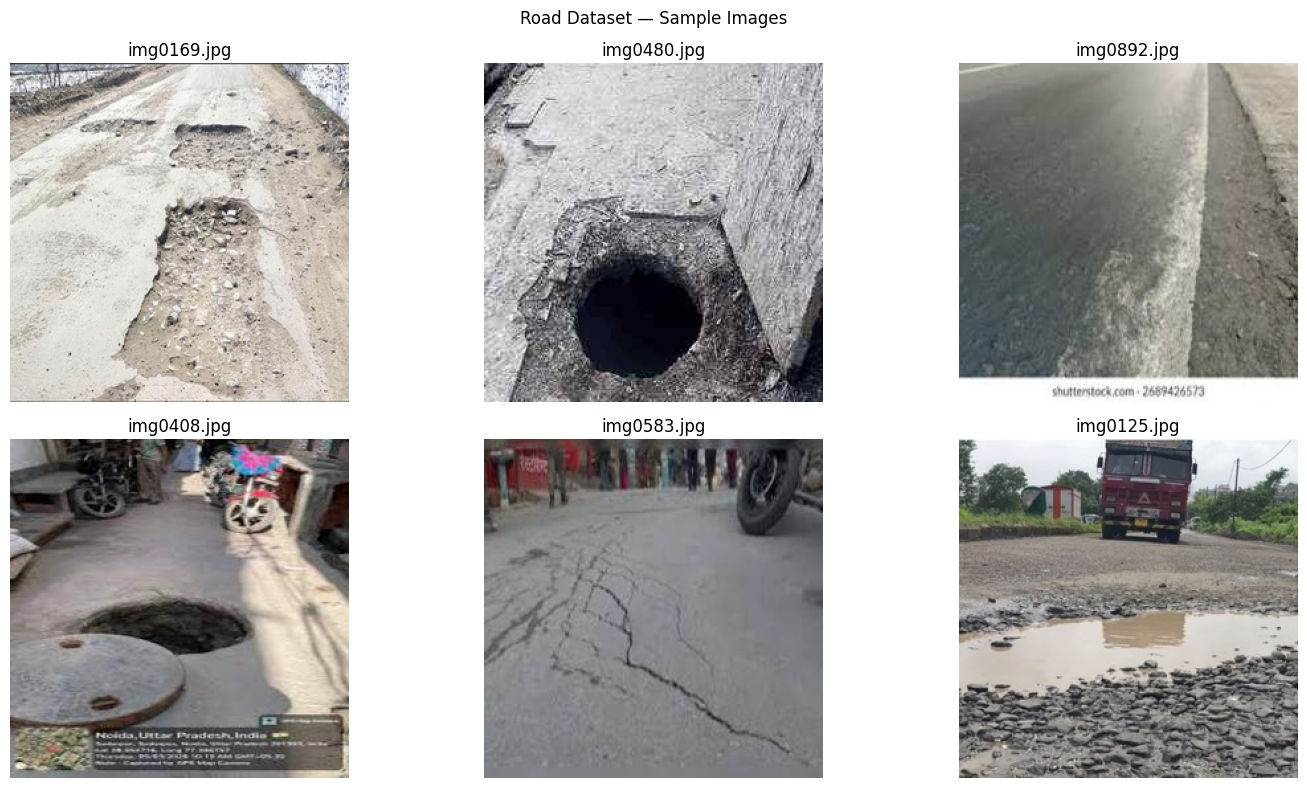

In [7]:

import random
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and ".git" not in p.parts
]

if not image_files:
    raise ValueError(
        "No images found. Check the dataset download and folder structure."
    )

samples = random.sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, image_path in zip(axes, samples):
    try:
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(image_path.name[:35])
        ax.axis("off")
    except Exception as e:
        ax.set_title(f"Could not load: {image_path.name}")
        ax.axis("off")
        print("Image error:", image_path, e)

for ax in axes[len(samples):]:
    ax.axis("off")

plt.suptitle("Road Dataset — Sample Images")
plt.tight_layout()
plt.show()


In [8]:

from pathlib import Path
from collections import Counter
import json
import pandas as pd

DATASET_DIR = Path("/content/road_surface_dataset")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and ".git" not in p.parts
]

print("Total images:", len(image_files))

# Check whether the dataset uses class folders
folder_counts = Counter()

for image_path in image_files:
    relative_path = image_path.relative_to(DATASET_DIR)
    if len(relative_path.parts) >= 2:
        folder_counts[relative_path.parts[0]] += 1

print("\nTop-level image distribution:")
for folder, count in folder_counts.most_common(20):
    print(f"{folder}: {count}")

# Show annotation file names
print("\nAnnotation files:")
annotation_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".csv", ".json", ".xml", ".txt"}
    and ".git" not in p.parts
]

for file in annotation_files[:40]:
    print(file.relative_to(DATASET_DIR))

# Inspect any CSV column names
print("\nCSV annotation summaries:")
for file in list(DATASET_DIR.rglob("*.csv"))[:5]:
    try:
        df = pd.read_csv(file)
        print(f"\n{file.name}: {df.shape}")
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    except Exception as error:
        print(file.name, error)


Total images: 1049

Top-level image distribution:
images: 1049

Annotation files:
metadata/dataset_metadata.csv
splits/test.txt
splits/val.txt
splits/train.txt
annotations/labels.csv

CSV annotation summaries:

dataset_metadata.csv: (1200, 6)
Columns: ['image_id', 'filename', 'label', 'annotator', 'date', 'source']


,image_id,filename,label,annotator,date,source
0,1,img0001.jpg,pothole,Kushal,04-03-2026,The Tribune
1,2,img0002.jpg,pothole,Kushal,04-03-2026,The Tribune
2,3,img0003.jpg,pothole,Kushal,04-03-2026,The Tribune



labels.csv: (1200, 2)
Columns: ['image', 'label']


,image,label
0,images/potholes/img0001.jpg,pothole
1,images/potholes/img0002.jpg,pothole
2,images/potholes/img0003.jpg,pothole


In [9]:

# Find directories that directly contain images
class_directories = []

for directory in sorted(DATASET_DIR.rglob("*")):
    if not directory.is_dir() or ".git" in directory.parts:
        continue

    images = [
        p for p in directory.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if len(images) >= 2:
        class_directories.append((directory, len(images)))

print("Potential class directories:", len(class_directories))

if len(class_directories) >= 2:
    print("\nFolder-based classification may be possible.")
    print("Detected folders:")
    for directory, count in class_directories:
        print(f"{directory.relative_to(DATASET_DIR)}: {count} images")
else:
    print("\nFolder-based classification is not yet verified.")
    print("We must map the annotation labels to image paths before training.")


Potential class directories: 6

Folder-based classification may be possible.
Detected folders:
images/broken_edges: 147 images
images/construction_zones: 102 images
images/cracks: 200 images
images/open_manholes: 200 images
images/potholes: 200 images
images/waterlogged_roads: 200 images


In [10]:

from pathlib import Path
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt

DATASET_DIR = Path("/content/road_surface_dataset")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and ".git" not in p.parts
]

valid_images = []
invalid_images = []

for path in image_files:
    try:
        with Image.open(path) as img:
            img.verify()
        valid_images.append(path)
    except Exception:
        invalid_images.append(path)

print("Total images:", len(image_files))
print("Valid images:", len(valid_images))
print("Invalid images:", len(invalid_images))

if invalid_images:
    print("\nFirst invalid images:")
    for path in invalid_images[:10]:
        print(path)


Total images: 1049
Valid images: 1049
Invalid images: 0


Potential folder labels:
open_manholes: 200
cracks: 200
waterlogged_roads: 200
potholes: 200
broken_edges: 147
construction_zones: 102


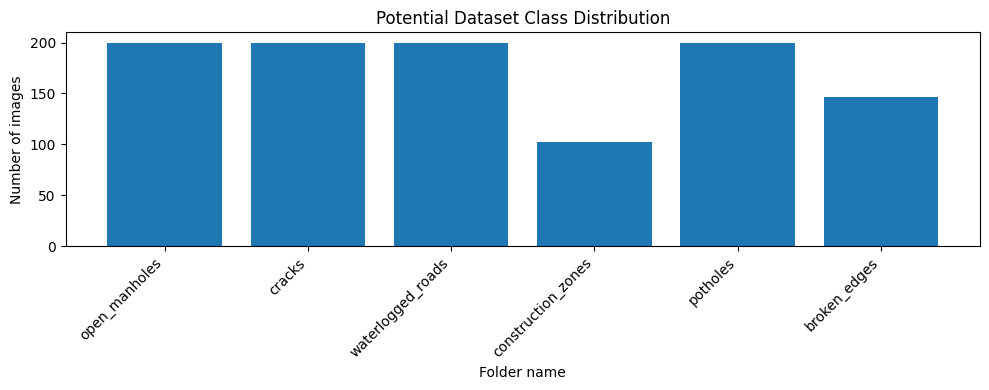

In [11]:

from collections import Counter

# A class folder is a directory whose immediate parent
# contains images belonging to the same class.
class_counts = Counter()

for path in valid_images:
    relative = path.relative_to(DATASET_DIR)

    if len(relative.parts) >= 2:
        class_name = relative.parts[-2]
        class_counts[class_name] += 1

print("Potential folder labels:")
for label, count in class_counts.most_common():
    print(f"{label}: {count}")

if len(class_counts) > 1:
    plt.figure(figsize=(10, 4))
    plt.bar(class_counts.keys(), class_counts.values())
    plt.title("Potential Dataset Class Distribution")
    plt.xlabel("Folder name")
    plt.ylabel("Number of images")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print(
        "\nMultiple class labels were not identified. "
        "Use the dataset annotation files to determine labels."
    )


In [12]:

from pathlib import Path

DATASET_DIR = Path("/content/road_surface_dataset")

print("SEARCHING FOR DATASET SPLITS AND LABELS")
print("=" * 55)

keywords = [
    "train", "test", "valid", "val", "label",
    "annot", "class", "data", "image"
]

for path in sorted(DATASET_DIR.rglob("*")):
    if not path.is_file() or ".git" in path.parts:
        continue

    name = path.name.lower()

    if any(keyword in name for keyword in keywords):
        print(path.relative_to(DATASET_DIR))


SEARCHING FOR DATASET SPLITS AND LABELS
annotations/labels.csv
docs/class_definitions.md
metadata/dataset_metadata.csv
splits/test.txt
splits/train.txt
splits/val.txt


In [13]:

from pathlib import Path

DATASET_DIR = Path("/content/road_surface_dataset")

candidate_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".txt", ".yaml", ".yml"}
    and ".git" not in p.parts
    and any(word in p.name.lower() for word in
            ["train", "test", "valid", "val", "data", "class"])
]

for file in candidate_files[:10]:
    print(f"\n--- {file.relative_to(DATASET_DIR)} ---")

    try:
        with open(file, "r", encoding="utf-8", errors="replace") as f:
            print(f.read(1500))
    except Exception as error:
        print("Could not read file:", error)

if not candidate_files:
    print("No matching text-based split files found.")



--- splits/test.txt ---
images/pothole/img0141
images/pothole/img0142
images/pothole/img0143
images/pothole/img0144
images/pothole/img0145
images/pothole/img0146
images/pothole/img0147
images/pothole/img0148
images/pothole/img0149
images/pothole/img0150
images/pothole/img0151
images/pothole/img0152
images/pothole/img0153
images/pothole/img0154
images/pothole/img0155
images/pothole/img0156
images/pothole/img0157
images/pothole/img0158
images/pothole/img0159
images/pothole/img0160
images/pothole/img0161
images/pothole/img0162
images/pothole/img0163
images/pothole/img0164
images/pothole/img0165
images/pothole/img0166
images/pothole/img0167
images/pothole/img0168
images/pothole/img0169
images/pothole/img0170
images/crack/img0541
images/crack/img0542
images/crack/img0543
images/crack/img0544
images/crack/img0545
images/crack/img0546
images/crack/img0547
images/crack/img0548
images/crack/img0549
images/crack/img0550
images/crack/img0551
images/crack/img0552
images/crack/img0553
images/crack

In [14]:

from pathlib import Path
import json
import xml.etree.ElementTree as ET

DATASET_DIR = Path("/content/road_surface_dataset")

# Inspect JSON annotations
json_files = [
    p for p in DATASET_DIR.rglob("*.json")
    if ".git" not in p.parts
]

for file in json_files[:5]:
    print(f"\nJSON: {file.relative_to(DATASET_DIR)}")

    try:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        if isinstance(data, dict):
            print("Keys:", list(data.keys())[:20])

            for key, value in list(data.items())[:5]:
                if isinstance(value, list):
                    print(key, "records:", len(value))
                    if value:
                        print("Example:", value[0])
                elif isinstance(value, dict):
                    print(key, "keys:", list(value.keys())[:10])
                else:
                    print(key, "=", str(value)[:200])

        elif isinstance(data, list):
            print("Records:", len(data))
            print("Example:", data[0] if data else "Empty")

    except Exception as error:
        print("JSON inspection error:", error)

# Inspect XML annotations
xml_files = [
    p for p in DATASET_DIR.rglob("*.xml")
    if ".git" not in p.parts
]

for file in xml_files[:5]:
    print(f"\nXML: {file.relative_to(DATASET_DIR)}")

    try:
        root = ET.parse(file).getroot()
        print("Root:", root.tag)

        for obj in root.findall(".//object")[:5]:
            print("Label:", obj.findtext("name"))
    except Exception as error:
        print("XML inspection error:", error)

if not json_files and not xml_files:
    print("No JSON/XML annotations found. Check CSV and TXT files instead.")


No JSON/XML annotations found. Check CSV and TXT files instead.


In [15]:

from pathlib import Path

DATASET_DIR = Path("/content/road_surface_dataset")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_count = sum(
    1 for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_extensions
    and ".git" not in p.parts
)

annotation_count = sum(
    1 for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".csv", ".json", ".xml", ".txt"}
    and ".git" not in p.parts
)

print("Dataset:", DATASET_DIR)
print("Images:", image_count)
print("Annotation/split files:", annotation_count)

if image_count == 0:
    print("ACTION: Fix the dataset download before proceeding.")
elif annotation_count == 0:
    print("ACTION: Inspect the repository structure for other label formats.")
else:
    print("ACTION: Use the annotation output from Cell 14 to map image labels.")


Dataset: /content/road_surface_dataset
Images: 1049
Annotation/split files: 5
ACTION: Use the annotation output from Cell 14 to map image labels.


In [16]:

from pathlib import Path
import pandas as pd
import json

DATASET_DIR = Path("/content/road_surface_dataset")

print("DATASET LABEL FORMAT CHECK")
print("=" * 55)

# 1. Inspect CSV files
for file in list(DATASET_DIR.rglob("*.csv"))[:10]:
    try:
        df = pd.read_csv(file)
        print(f"\nCSV: {file.relative_to(DATASET_DIR)}")
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    except Exception as e:
        print("CSV error:", file.name, e)

# 2. Inspect JSON structure
for file in list(DATASET_DIR.rglob("*.json"))[:10]:
    try:
        with open(file, "r", encoding="utf-8") as f:
            data = json.load(f)

        print(f"\nJSON: {file.relative_to(DATASET_DIR)}")

        if isinstance(data, dict):
            print("Keys:", list(data.keys())[:15])
        elif isinstance(data, list):
            print("Number of records:", len(data))
            if data:
                print("First record:", data[0])

    except Exception as e:
        print("JSON error:", file.name, e)

# 3. Find YAML configuration files
for file in list(DATASET_DIR.rglob("*.yaml"))[:5]:
    print(f"\nYAML: {file.relative_to(DATASET_DIR)}")
    print(file.read_text(errors="replace")[:2000])

for file in list(DATASET_DIR.rglob("*.yml"))[:5]:
    print(f"\nYML: {file.relative_to(DATASET_DIR)}")
    print(file.read_text(errors="replace")[:2000])


DATASET LABEL FORMAT CHECK

CSV: metadata/dataset_metadata.csv
Columns: ['image_id', 'filename', 'label', 'annotator', 'date', 'source']


,image_id,filename,label,annotator,date,source
0,1,img0001.jpg,pothole,Kushal,04-03-2026,The Tribune
1,2,img0002.jpg,pothole,Kushal,04-03-2026,The Tribune
2,3,img0003.jpg,pothole,Kushal,04-03-2026,The Tribune



CSV: annotations/labels.csv
Columns: ['image', 'label']


,image,label
0,images/potholes/img0001.jpg,pothole
1,images/potholes/img0002.jpg,pothole
2,images/potholes/img0003.jpg,pothole


In [17]:

from pathlib import Path
from collections import Counter
from PIL import Image
import pandas as pd

DATASET_DIR = Path("/content/road_surface_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        "Dataset folder not found. Run the download cell first."
    )

images = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
    and ".git" not in p.parts
]

print("=" * 55)
print("ROAD SURFACE DATASET REPORT")
print("=" * 55)
print("Dataset path:", DATASET_DIR)
print("Total images:", len(images))

# Identify images grouped by their parent folder
parent_counts = Counter(p.parent.name for p in images)

print("\nImages by immediate parent folder:")
for name, count in parent_counts.most_common(30):
    print(f"{name}: {count}")

# Validate a small sample of image files
print("\nChecking sample image integrity:")
for path in images[:10]:
    try:
        with Image.open(path) as img:
            img.verify()
        print("OK:", path.relative_to(DATASET_DIR))
    except Exception as error:
        print("INVALID:", path.name, error)

# List annotation files
annotation_extensions = {".csv", ".json", ".xml", ".txt", ".yaml", ".yml"}

annotation_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in annotation_extensions
    and ".git" not in p.parts
]

print("\nAnnotation and configuration files:", len(annotation_files))
for path in annotation_files[:30]:
    print(path.relative_to(DATASET_DIR))

# Preview CSV metadata
for path in [p for p in annotation_files if p.suffix.lower() == ".csv"][:3]:
    try:
        df = pd.read_csv(path)
        print(f"\nCSV preview: {path.name}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    except Exception as error:
        print("Could not read", path.name, error)

print("\nReport complete.")


ROAD SURFACE DATASET REPORT
Dataset path: /content/road_surface_dataset
Total images: 1049

Images by immediate parent folder:
open_manholes: 200
cracks: 200
waterlogged_roads: 200
potholes: 200
broken_edges: 147
construction_zones: 102

Checking sample image integrity:
OK: images/open_manholes/img0371.jpg
OK: images/open_manholes/img0349.jpg
OK: images/open_manholes/img0440.jpg
OK: images/open_manholes/img0386.jpg
OK: images/open_manholes/img0481.jpg
OK: images/open_manholes/img0479.jpg
OK: images/open_manholes/img0405.jpg
OK: images/open_manholes/img0381.jpg
OK: images/open_manholes/img0498.jpg
OK: images/open_manholes/img0353.jpg

Annotation and configuration files: 5
metadata/dataset_metadata.csv
splits/test.txt
splits/val.txt
splits/train.txt
annotations/labels.csv

CSV preview: dataset_metadata.csv
Shape: (1200, 6)
Columns: ['image_id', 'filename', 'label', 'annotator', 'date', 'source']


,image_id,filename,label,annotator,date,source
0,1,img0001.jpg,pothole,Kushal,04-03-2026,The Tribune
1,2,img0002.jpg,pothole,Kushal,04-03-2026,The Tribune
2,3,img0003.jpg,pothole,Kushal,04-03-2026,The Tribune



CSV preview: labels.csv
Shape: (1200, 2)
Columns: ['image', 'label']


,image,label
0,images/potholes/img0001.jpg,pothole
1,images/potholes/img0002.jpg,pothole
2,images/potholes/img0003.jpg,pothole



Report complete.


In [18]:

from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/road_surface_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError("Run the dataset download cell first.")

# Identify directories with images directly inside them
class_dirs = []

for folder in DATASET_DIR.rglob("*"):
    if not folder.is_dir() or ".git" in folder.parts:
        continue

    image_count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if image_count:
        class_dirs.append((folder, image_count))

print("Potential image folders:")
for folder, count in class_dirs:
    print(f"{folder.relative_to(DATASET_DIR)}: {count} images")

# Detect conventional class-folder layout
class_names = {
    "good", "normal", "smooth", "bad", "poor",
    "pothole", "crack", "cracked", "wet", "dry",
    "damaged", "undamaged"
}

recognized = [
    (folder, count)
    for folder, count in class_dirs
    if folder.name.lower() in class_names
]

print("\nRecognized class-name folders:", len(recognized))

if len(recognized) >= 2:
    print("Possible class folders found.")
    print("Next: verify that these folders represent independent classes.")
else:
    print(
        "No reliable class-folder layout detected.\n"
        "Use the dataset's actual annotation format to create labels "
        "before training."
    )


Potential image folders:
images/open_manholes: 200 images
images/cracks: 200 images
images/waterlogged_roads: 200 images
images/construction_zones: 102 images
images/potholes: 200 images
images/broken_edges: 147 images

Recognized class-name folders: 0
No reliable class-folder layout detected.
Use the dataset's actual annotation format to create labels before training.


In [19]:

from pathlib import Path

DATASET_DIR = Path("/content/road_surface_dataset")

print("README AND CONFIGURATION FILES")
print("=" * 55)

readme_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.name.lower().startswith("readme")
    and ".git" not in p.parts
]

config_files = [
    p for p in DATASET_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".yaml", ".yml"}
    and ".git" not in p.parts
]

for file in readme_files[:3] + config_files[:5]:
    print(f"\n--- {file.relative_to(DATASET_DIR)} ---")
    try:
        print(file.read_text(encoding="utf-8", errors="replace")[:5000])
    except Exception as error:
        print("Could not read:", error)

if not readme_files and not config_files:
    print("No README or YAML configuration files found.")

print("\nTOP-LEVEL CONTENTS")
for item in sorted(DATASET_DIR.iterdir()):
    print(("[DIR] " if item.is_dir() else "[FILE] ") + item.name)


README AND CONFIGURATION FILES

--- README.md ---
Indian Road Damage & Infrastructure Dataset (IRDID)
Overview

The Indian Road Damage & Infrastructure Dataset (IRDID) is a curated computer vision dataset designed to capture common road damage and infrastructure issues in Indian road environments. While existing datasets such as the Road Damage Dataset (RDD) include images from multiple countries, including India, they do not fully capture the diversity and complexity of Indian road conditions. Indian roads often feature unmarked lanes, mixed road materials, informal infrastructure, heavy traffic interactions, and seasonal damage caused by monsoons.

This dataset aims to provide a structured and diverse collection of images representing typical road hazards in India to support research and development of computer vision models for road monitoring, infrastructure assessment, and smart city applications.

Dataset Classes

The dataset contains six classes of road damage and infrastructure

In [20]:

from pathlib import Path
import subprocess

DATASET_DIR = Path("/content/road_surface_dataset")

if not DATASET_DIR.exists():
    raise FileNotFoundError("Dataset folder not found. Run Cell 1 first.")

result = subprocess.run(
    ["git", "-C", str(DATASET_DIR), "ls-files"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    tracked_files = result.stdout.splitlines()

    print("Tracked files:", len(tracked_files))
    print("\nFirst 100 tracked files:")

    for filename in tracked_files[:100]:
        print(filename)

    if not tracked_files:
        print("No tracked files found.")
else:
    print("Git inspection failed:")
    print(result.stderr)

print("\nRepository top-level entries:")
for path in sorted(DATASET_DIR.iterdir()):
    print(
        "[DIR] " if path.is_dir() else "[FILE] ",
        path.name
    )


Tracked files: 1057

First 100 tracked files:
LICENSE
README.md
annotations/labels.csv
docs/class_definitions.md
images/broken_edges/img0801.jpg
images/broken_edges/img0802.jpg
images/broken_edges/img0803.jpg
images/broken_edges/img0804.jpg
images/broken_edges/img0805.jpg
images/broken_edges/img0806.jpg
images/broken_edges/img0807.jpg
images/broken_edges/img0808.jpg
images/broken_edges/img0809.jpg
images/broken_edges/img0810.jpg
images/broken_edges/img0811.jpg
images/broken_edges/img0812.jpg
images/broken_edges/img0813.jpg
images/broken_edges/img0814.jpg
images/broken_edges/img0815.jpg
images/broken_edges/img0816.jpg
images/broken_edges/img0817.jpg
images/broken_edges/img0818.jpg
images/broken_edges/img0819.jpg
images/broken_edges/img0820.jpg
images/broken_edges/img0821.jpg
images/broken_edges/img0822.jpg
images/broken_edges/img0823.jpg
images/broken_edges/img0824.jpg
images/broken_edges/img0825.jpg
images/broken_edges/img0826.jpg
images/broken_edges/img0827.jpg
images/broken_edges/img

In [21]:

from pathlib import Path
import subprocess

DATASET_DIR = Path("/content/road_surface_dataset")

print("Checking dataset repository...\n")

if DATASET_DIR.exists():
    result = subprocess.run(
        ["git", "-C", str(DATASET_DIR), "remote", "-v"],
        capture_output=True,
        text=True
    )
    print("Repository remote:")
    print(result.stdout or result.stderr)

    result = subprocess.run(
        ["git", "-C", str(DATASET_DIR), "log", "-1", "--oneline"],
        capture_output=True,
        text=True
    )
    print("Latest commit:")
    print(result.stdout or result.stderr)

    image_count = sum(
        1 for p in DATASET_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        and ".git" not in p.parts
    )
    print("Downloaded images:", image_count)
else:
    print("Dataset directory does not exist.")


Checking dataset repository...

Repository remote:
origin	https://github.com/ahs695/Indian-Road-Damage-Infrastructure-Dataset.git (fetch)
origin	https://github.com/ahs695/Indian-Road-Damage-Infrastructure-Dataset.git (push)

Latest commit:
98b1260 readme and lic

Downloaded images: 1049


In [22]:

from pathlib import Path
import pandas as pd
import json

DATASET_DIR = Path("/content/road_surface_dataset")

if not DATASET_DIR.exists():
    raise FileNotFoundError("Dataset not found. Run Cell 1 first.")

# Find image classification metadata
csv_files = list(DATASET_DIR.rglob("*.csv"))
json_files = list(DATASET_DIR.rglob("*.json"))

print("CSV files:", len(csv_files))
print("JSON files:", len(json_files))

for path in csv_files[:3]:
    print(f"\nCSV: {path.relative_to(DATASET_DIR)}")
    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())
    display(df.head(5))

for path in json_files[:3]:
    print(f"\nJSON: {path.relative_to(DATASET_DIR)}")
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    if isinstance(data, dict):
        print("Keys:", list(data.keys())[:20])
    elif isinstance(data, list):
        print("Records:", len(data))
        print("Example:", data[0] if data else "Empty")

print("\nLabel inspection complete.")


CSV files: 2
JSON files: 0

CSV: metadata/dataset_metadata.csv
Columns: ['image_id', 'filename', 'label', 'annotator', 'date', 'source']


,image_id,filename,label,annotator,date,source
0,1,img0001.jpg,pothole,Kushal,04-03-2026,The Tribune
1,2,img0002.jpg,pothole,Kushal,04-03-2026,The Tribune
2,3,img0003.jpg,pothole,Kushal,04-03-2026,The Tribune
3,4,img0004.jpg,pothole,Kushal,04-03-2026,The Tribune
4,5,img0005.jpg,pothole,Kushal,04-03-2026,The Tribune



CSV: annotations/labels.csv
Columns: ['image', 'label']


,image,label
0,images/potholes/img0001.jpg,pothole
1,images/potholes/img0002.jpg,pothole
2,images/potholes/img0003.jpg,pothole
3,images/potholes/img0004.jpg,pothole
4,images/potholes/img0005.jpg,pothole



Label inspection complete.


In [23]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("\nGPU available:")
    for gpu in gpus:
        print(gpu)
else:
    print("\nNo GPU detected. CPU training is possible but may be slower.")
    print("In Colab, select Runtime > Change runtime type > T4 GPU if available.")

print("\nDataset directory exists:",
      Path("/content/road_surface_dataset").exists())


TensorFlow version: 2.21.0
NumPy version: 2.1.3

GPU available:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Dataset directory exists: True


In [24]:

from pathlib import Path
import tensorflow as tf

DATASET_DIR = Path("/content/road_surface_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find directories that contain images directly
class_dirs = []

for folder in sorted(DATASET_DIR.rglob("*")):
    if not folder.is_dir() or ".git" in folder.parts:
        continue

    count = sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if count >= 2:
        class_dirs.append((folder, count))

print("Candidate folders:")
for folder, count in class_dirs:
    print(f"{folder.relative_to(DATASET_DIR)}: {count} images")

# Stop if there is no confirmed class-folder structure
if len(class_dirs) < 2:
    raise ValueError(
        "The dataset does not have a verified class-folder structure. "
        "Do not train yet. We must first map the real annotation labels "
        "to the image paths."
    )

print(
    "\nCandidate folders detected. Verify that each folder represents "
    "a distinct road-surface class before training."
)


Candidate folders:
images/broken_edges: 147 images
images/construction_zones: 102 images
images/cracks: 200 images
images/open_manholes: 200 images
images/potholes: 200 images
images/waterlogged_roads: 200 images

Candidate folders detected. Verify that each folder represents a distinct road-surface class before training.


In [25]:

from pathlib import Path
from collections import Counter

DATASET_DIR = Path("/content/road_surface_dataset")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError("Dataset not found. Run Cell 1 first.")

image_paths = []
labels = []

# A valid class folder must contain images directly.
for folder in sorted(DATASET_DIR.rglob("*")):
    if not folder.is_dir() or ".git" in folder.parts:
        continue

    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if len(files) >= 2:
        # Exclude conventional dataset split directories.
        if folder.name.lower() in {"train", "test", "val", "valid", "images"}:
            continue

        for p in files:
            image_paths.append(str(p))
            labels.append(folder.name)

counts = Counter(labels)

print("Candidate labeled images:", len(image_paths))
print("Candidate classes:", len(counts))

for name, count in sorted(counts.items()):
    print(f"{name}: {count}")

if len(counts) < 2:
    print(
        "\nSTOP: No reliable class-folder dataset detected. "
        "We need the repository's actual annotation schema "
        "before creating training labels."
    )
else:
    print(
        "\nCandidate labels found. Verify that the folders represent "
        "real road-condition classes before training."
    )


Candidate labeled images: 1049
Candidate classes: 6
broken_edges: 147
construction_zones: 102
cracks: 200
open_manholes: 200
potholes: 200
waterlogged_roads: 200

Candidate labels found. Verify that the folders represent real road-condition classes before training.


In [26]:

import numpy as np
from sklearn.model_selection import train_test_split
from collections import Counter

# Requires image_paths and labels from Cell 26.
if "image_paths" not in globals() or "labels" not in globals():
    raise RuntimeError("Run Cell 26 first.")

if len(set(labels)) < 2:
    raise ValueError(
        "At least two verified classes are required. "
        "Use the actual dataset annotations to create labels first."
    )

class_counts = Counter(labels)
small_classes = {
    name: count for name, count in class_counts.items()
    if count < 3
}

if small_classes:
    raise ValueError(
        f"Some classes have fewer than 3 images: {small_classes}. "
        "More labeled data is needed for a reliable split."
    )

X = np.array(image_paths)
y = np.array(labels)

# 70% training, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("\nClasses:", sorted(set(y)))

print("\nTraining class distribution:")
print(Counter(y_train))


Training images: 734
Validation images: 157
Test images: 158

Classes: [np.str_('broken_edges'), np.str_('construction_zones'), np.str_('cracks'), np.str_('open_manholes'), np.str_('potholes'), np.str_('waterlogged_roads')]

Training class distribution:
Counter({np.str_('cracks'): 140, np.str_('open_manholes'): 140, np.str_('waterlogged_roads'): 140, np.str_('potholes'): 140, np.str_('broken_edges'): 103, np.str_('construction_zones'): 71})


In [27]:

import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create consistent numeric labels
class_names = sorted(set(labels))
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

y_train_num = np.array([class_to_index[x] for x in y_train])
y_val_num = np.array([class_to_index[x] for x in y_val])
y_test_num = np.array([class_to_index[x] for x in y_test])

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

def make_dataset(paths, numeric_labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, numeric_labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = make_dataset(X_train, y_train_num, training=True)
val_ds = make_dataset(X_val, y_val_num)
test_ds = make_dataset(X_test, y_test_num)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("Class names:", class_names)


Training batches: 23
Validation batches: 5
Test batches: 5
Class names: ['broken_edges', 'construction_zones', 'cracks', 'open_manholes', 'potholes', 'waterlogged_roads']


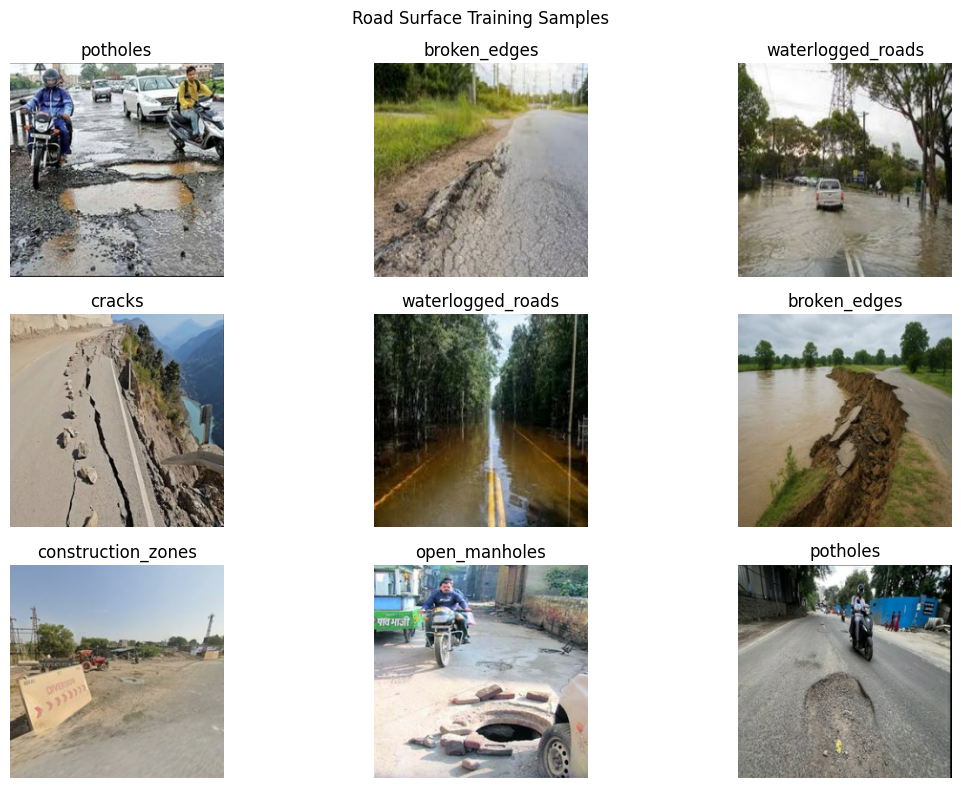

In [28]:

import matplotlib.pyplot as plt

images, numeric_labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(
        tf.cast(tf.clip_by_value(images[i], 0, 255), tf.uint8).numpy()
    )
    plt.title(class_names[int(numeric_labels[i].numpy())])
    plt.axis("off")

plt.suptitle("Road Surface Training Samples")
plt.tight_layout()
plt.show()


In [29]:

import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = (224, 224)
NUM_CLASSES = len(class_names)

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")

# Pretrained feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Initially freeze pretrained layers
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# Convert pixels from [0, 255] to [-1, 1]
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [30]:

from pathlib import Path

MODEL_DIR = Path("/content/road_surface_outputs")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(MODEL_DIR / "best_mobilenetv2.keras"),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.2978 - loss: 1.9072
Epoch 1: val_accuracy improved from None to 0.61146, saving model to /content/road_surface_outputs/best_mobilenetv2.keras

Epoch 1: finished saving model to /content/road_surface_outputs/best_mobilenetv2.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 17s 181ms/step - accuracy: 0.3174 - loss: 1.7714 - val_accuracy: 0.6115 - val_loss: 1.2159 - learning_rate: 3.0000e-04
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5035 - loss: 1.2494
Epoch 2: val_accuracy improved from 0.61146 to 0.73248, saving model to /content/road_surface_outputs/best_mobilenetv2.keras

Epoch 2: finished saving model to /content/road_surface_outputs/best_mobilenetv2.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.5286 - loss: 1.2208 - val_accuracy: 0.7325 - val_loss: 0.8870 - learning_rate: 3.0000e-04
Epoch 3/20
22/23 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.6615 - loss: 0.9715
Epoch 3: val_accuracy improved 

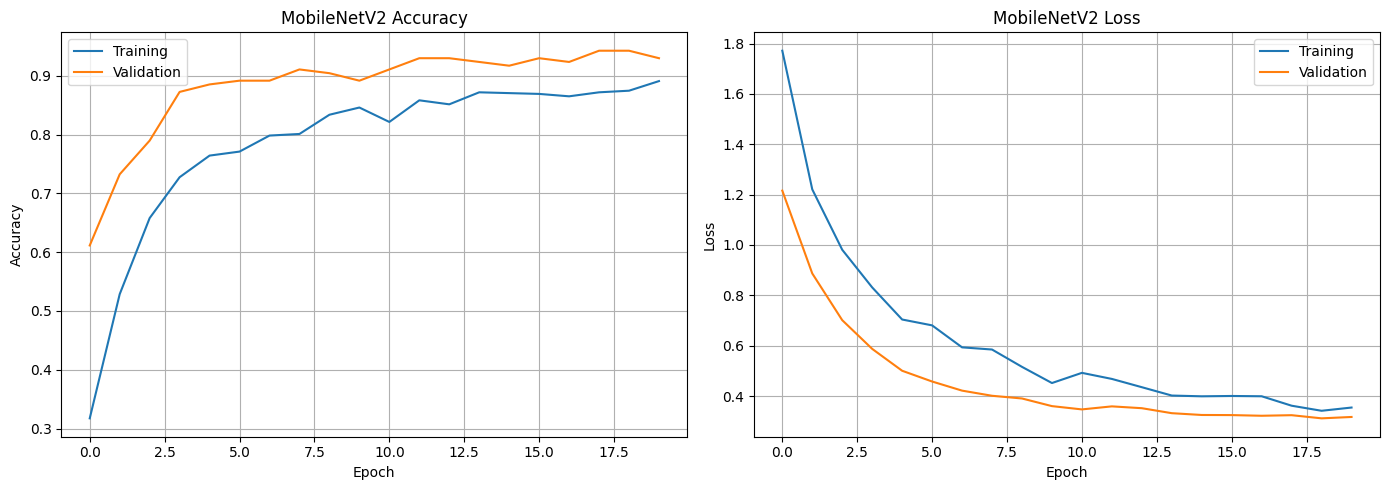

Best validation accuracy: 94.27%


In [31]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("MobileNetV2 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("MobileNetV2 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best validation accuracy:",
      f"{max(history.history['val_accuracy'])*100:.2f}%")


In [32]:

# Unfreeze the base model, but keep most layers frozen
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(MODEL_DIR / "best_finetuned_road_model.keras"),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

fine_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

print(
    "Best fine-tuning validation accuracy:",
    f"{max(fine_history.history['val_accuracy'])*100:.2f}%"
)


Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.8997 - loss: 0.3359
Epoch 1: val_accuracy improved from None to 0.93631, saving model to /content/road_surface_outputs/best_finetuned_road_model.keras

Epoch 1: finished saving model to /content/road_surface_outputs/best_finetuned_road_model.keras
23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 184ms/step - accuracy: 0.8937 - loss: 0.3400 - val_accuracy: 0.9363 - val_loss: 0.3056
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9007 - loss: 0.3413
Epoch 2: val_accuracy did not improve from 0.93631
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - accuracy: 0.8951 - loss: 0.3392 - val_accuracy: 0.9299 - val_loss: 0.2811
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9041 - loss: 0.3412
Epoch 3: val_accuracy did not improve from 0.93631
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9005 - loss: 0.3172 - val_accuracy: 0.9299 - val_loss: 0.2904
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.

In [33]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, accuracy_score

# Load the best fine-tuned model if it exists
from pathlib import Path

best_path = Path(
    "/content/road_surface_outputs/best_finetuned_road_model.keras"
)

if best_path.exists():
    model = tf.keras.models.load_model(best_path)
    print("Loaded best fine-tuned model.")
else:
    print("Using the currently trained model.")

# Generate test predictions
y_true = np.concatenate([
    labels.numpy() if tf.is_tensor(labels) else labels
    for _, labels in test_ds
])

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_true, y_pred)

print(f"\nTest accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)


Loaded best fine-tuned model.
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 312ms/step

Test accuracy: 90.51%

Classification report:
                    precision    recall  f1-score   support

      broken_edges       0.89      0.77      0.83        22
construction_zones       0.80      1.00      0.89        16
            cracks       0.87      0.90      0.89        30
     open_manholes       0.97      0.93      0.95        30
          potholes       0.93      0.90      0.92        30
 waterlogged_roads       0.93      0.93      0.93        30

          accuracy                           0.91       158
         macro avg       0.90      0.91      0.90       158
      weighted avg       0.91      0.91      0.90       158



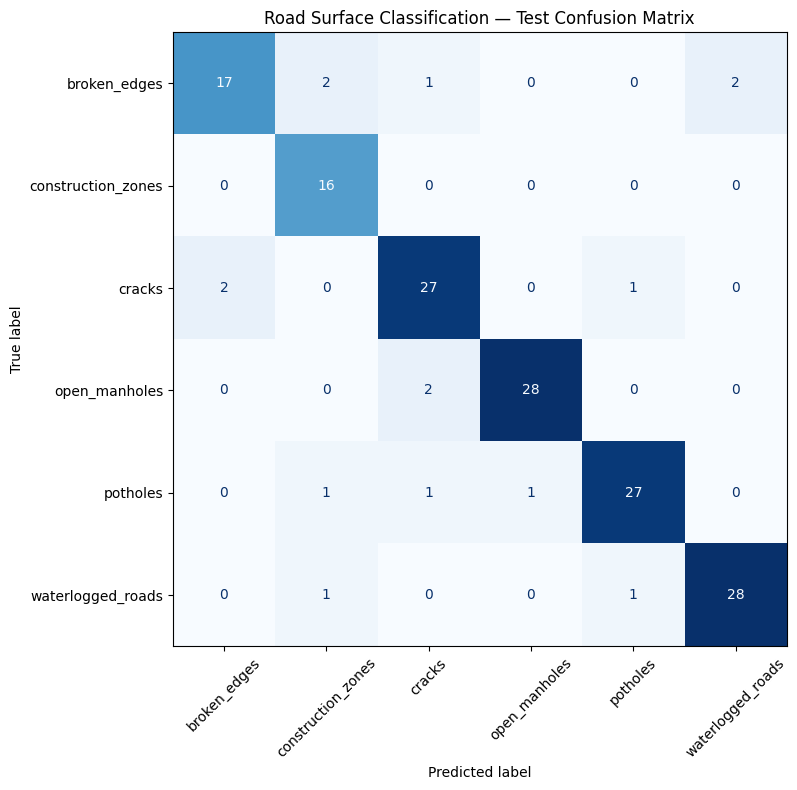

In [34]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Road Surface Classification — Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [35]:

import json
from pathlib import Path

OUTPUT_DIR = Path("/content/road_surface_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model.save(OUTPUT_DIR / "road_surface_classifier.keras")

with open(OUTPUT_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("Model saved:", OUTPUT_DIR / "road_surface_classifier.keras")
print("Class labels saved:", OUTPUT_DIR / "class_names.json")
print("Test accuracy:", f"{test_accuracy * 100:.2f}%")


Model saved: /content/road_surface_outputs/road_surface_classifier.keras
Class labels saved: /content/road_surface_outputs/class_names.json
Test accuracy: 90.51%


In [36]:

%pip install -q gradio


In [37]:

import time
from pathlib import Path

start = time.time()

MODEL_PATH = Path("/content/road_surface_outputs/road_surface_classifier.keras")
LABEL_PATH = Path("/content/road_surface_outputs/class_names.json")

print("Model exists:", MODEL_PATH.exists())
print("Labels exist:", LABEL_PATH.exists())

if MODEL_PATH.exists():
    print("Model size:", round(MODEL_PATH.stat().st_size / (1024**2), 2), "MB")

import tensorflow as tf
print("TensorFlow imported:", tf.__version__)

import gradio as gr
print("Gradio imported:", gr.__version__)

print("Diagnostic time:", round(time.time() - start, 2), "seconds")



Model exists: True
Labels exist: True
Model size: 22.61 MB
TensorFlow imported: 2.21.0
Gradio imported: 6.30.0
Diagnostic time: 3.06 seconds


In [38]:

import json
import tensorflow as tf
from pathlib import Path

OUTPUT_DIR = Path("/content/road_surface_outputs")

model = tf.keras.models.load_model(
    OUTPUT_DIR / "road_surface_classifier.keras",
    compile=False
)

with open(OUTPUT_DIR / "class_names.json", "r") as f:
    class_names = json.load(f)

print("Model loaded. Classes:", class_names)


Model loaded. Classes: ['broken_edges', 'construction_zones', 'cracks', 'open_manholes', 'potholes', 'waterlogged_roads']


In [39]:
%pip install -q gradio reportlab

In [40]:

import html
import json
from pathlib import Path
from datetime import datetime

import gradio as gr
import numpy as np
import pandas as pd
import tensorflow as tf

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import mm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)

# ============================================================
# CRACK CATCHER - COMPLETE WEB APPLICATION
# ============================================================

OUTPUT_DIR = Path("/content/road_surface_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "road_surface_classifier.keras"
LABEL_PATH = OUTPUT_DIR / "class_names.json"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not LABEL_PATH.exists():
    raise FileNotFoundError(f"Labels not found: {LABEL_PATH}")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

with open(LABEL_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

if model.output_shape[-1] != len(class_names):
    raise ValueError("Model output and class labels do not match.")

prediction_history = []

NAVY = "#17365D"
TEAL = "#138A83"
BLUE = "#4776D0"
PALE = "#F4F7FB"

# ============================================================
# ROAD CONDITION INFORMATION
# ============================================================

CONDITION_INFO = {
    "potholes": {
        "priority": "High",
        "color": "#C94C4C",
        "description": "Visible potholes or localized pavement damage.",
        "action": "Inspect the affected area and assess repair requirements."
    },
    "broken_edges": {
        "priority": "High",
        "color": "#C94C4C",
        "description": "Possible broken or deteriorated road edges.",
        "action": "Inspect edge stability and the extent of pavement damage."
    },
    "open_manholes": {
        "priority": "High",
        "color": "#C94C4C",
        "description": "An open or exposed manhole may be present.",
        "action": "Arrange prompt on-site verification and appropriate protection."
    },
    "cracks": {
        "priority": "Medium",
        "color": "#D58A24",
        "description": "Visible cracking or fractures in the road surface.",
        "action": "Inspect crack severity and monitor further deterioration."
    },
    "waterlogged_roads": {
        "priority": "High",
        "color": "#C94C4C",
        "description": "Water accumulation may be visible on the road.",
        "action": "Inspect drainage and check for hidden pavement damage."
    },
    "construction_zones": {
        "priority": "Review",
        "color": "#4776D0",
        "description": "The image may show a road construction area.",
        "action": "Verify traffic management and construction site conditions."
    }
}

# ============================================================
# IMAGE PREDICTION
# ============================================================

def analyze_road(image):
    empty_details = pd.DataFrame(
        columns=["Road condition", "Confidence (%)"]
    )

    empty_history = pd.DataFrame(columns=[
        "Time", "Prediction", "Confidence (%)", "Priority indicator"
    ])

    if image is None:
        return (
            "<div class='empty-result'>Upload a road image to begin.</div>",
            None, {}, empty_details,
            "Upload an image to receive maintenance guidance.",
            pd.DataFrame(prediction_history, columns=empty_history.columns)
        )

    # Preprocessing must match the model's training pipeline.
    processed_image = image.convert("RGB").resize((224, 224))
    array = np.asarray(processed_image, dtype=np.float32)[None, ...]

    probabilities = model.predict(array, verbose=0)[0]

    if len(probabilities) != len(class_names):
        raise gr.Error("Model output does not match class_names.json.")

    predicted_index = int(np.argmax(probabilities))
    predicted_class = str(class_names[predicted_index])
    confidence = float(probabilities[predicted_index]) * 100

    info = CONDITION_INFO.get(predicted_class, {
        "priority": "Review",
        "color": BLUE,
        "description": "A road-condition category was predicted.",
        "action": "Verify the result through an on-site inspection."
    })

    display_class = html.escape(
        predicted_class.replace("_", " ").title()
    )

    result_html = f"""
    <div class="result-card">
        <div class="result-top">
            <span class="result-label">PREDICTED CONDITION</span>
            <span class="priority-badge"
                  style="background:{info['color']}">
                {html.escape(info['priority'])} Priority
            </span>
        </div>

        <h2>{display_class}</h2>
        <p>{html.escape(info['description'])}</p>

        <div class="confidence-heading">
            <span>Model confidence</span>
            <strong>{confidence:.2f}%</strong>
        </div>

        <div class="confidence-track">
            <div class="confidence-fill"
                 style="width:{confidence:.2f}%;
                        background:{info['color']}"></div>
        </div>

        <p class="small-note">
            Confidence is a model score, not a guarantee of correctness.
        </p>
    </div>
    """

    scores = {
        str(class_names[i]): float(probabilities[i])
        for i in range(len(class_names))
    }

    details = pd.DataFrame({
        "Road condition": [
            str(name).replace("_", " ").title()
            for name in class_names
        ],
        "Confidence (%)": np.round(probabilities * 100, 2)
    }).sort_values(
        "Confidence (%)", ascending=False
    ).reset_index(drop=True)

    advice = f"""
### Recommended follow-up

**Priority:** {info['priority']}

**Suggested action:** {info['action']}

**Safety note:** This prediction is for informational purposes.
Confirm the actual road condition through an on-site inspection.
"""

    prediction_history.append({
        "Time": datetime.now().strftime("%d-%m-%Y %I:%M:%S %p"),
        "Prediction": predicted_class.replace("_", " ").title(),
        "Confidence (%)": round(confidence, 2),
        "Priority indicator": info["priority"]
    })

    return (
        result_html,
        processed_image,
        scores,
        details,
        advice,
        pd.DataFrame(prediction_history)
    )

# ============================================================
# PROFESSIONAL PDF REPORT
# ============================================================

def generate_pdf_report():
    if not prediction_history:
        raise gr.Error("Analyze at least one image before generating a report.")

    df = pd.DataFrame(prediction_history)

    report_path = OUTPUT_DIR / (
        f"Crack_Catcher_Report_{datetime.now():%Y%m%d_%H%M%S}.pdf"
    )

    navy = colors.HexColor(NAVY)
    teal = colors.HexColor(TEAL)
    pale = colors.HexColor(PALE)
    slate = colors.HexColor("#526579")
    border = colors.HexColor("#DCE5EF")

    styles = getSampleStyleSheet()

    styles.add(ParagraphStyle(
        name="CCTitle",
        fontName="Helvetica-Bold",
        fontSize=21,
        leading=26,
        textColor=colors.white
    ))

    styles.add(ParagraphStyle(
        name="CCSubtitle",
        fontName="Helvetica",
        fontSize=8,
        leading=12,
        textColor=colors.HexColor("#D9F2F0")
    ))

    styles.add(ParagraphStyle(
        name="CCSection",
        fontName="Helvetica-Bold",
        fontSize=12,
        leading=16,
        textColor=navy,
        spaceBefore=12,
        spaceAfter=7
    ))

    styles.add(ParagraphStyle(
        name="CCBody",
        fontName="Helvetica",
        fontSize=8.5,
        leading=12,
        textColor=colors.HexColor("#334155")
    ))

    styles.add(ParagraphStyle(
        name="CCSmall",
        fontName="Helvetica",
        fontSize=7.5,
        leading=10,
        textColor=slate
    ))

    def para(value, style="CCSmall"):
        text = "" if pd.isna(value) else str(value)
        text = (
            text.replace("&", "&amp;")
                .replace("<", "&lt;")
                .replace(">", "&gt;")
        )
        return Paragraph(text, styles[style])

    doc = SimpleDocTemplate(
        str(report_path),
        pagesize=A4,
        rightMargin=16 * mm,
        leftMargin=16 * mm,
        topMargin=18 * mm,
        bottomMargin=20 * mm,
        title="Crack Catcher Road Analysis Report",
        author="Crack Catcher"
    )

    story = []
    now = datetime.now()

    # Report title banner
    date_style = ParagraphStyle(
        "CCDate",
        fontName="Helvetica",
        fontSize=8.5,
        leading=13,
        alignment=TA_CENTER,
        textColor=colors.white
    )

    banner = Table([
        [
            Paragraph(
                "CRACK CATCHER<br/>ROAD ANALYSIS REPORT",
                styles["CCTitle"]
            ),
            Paragraph(
                f"<b>Generated</b><br/>{now:%d %B %Y}<br/>"
                f"{now:%I:%M %p}",
                date_style
            )
        ],
        [
            Paragraph(
                "CNN-POWERED ROAD CONDITION CLASSIFICATION",
                styles["CCSubtitle"]
            ),
            ""
        ]
    ], colWidths=[112 * mm, 52 * mm])

    banner.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, -1), navy),
        ("SPAN", (0, 1), (1, 1)),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 10),
        ("RIGHTPADDING", (0, 0), (-1, -1), 10),
        ("TOPPADDING", (0, 0), (-1, -1), 10),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 9)
    ]))

    story += [banner, Spacer(1, 7 * mm)]

    average_confidence = pd.to_numeric(
        df["Confidence (%)"], errors="coerce"
    ).mean()

    mode = df["Prediction"].mode()
    most_common = mode.iloc[0] if not mode.empty else "N/A"

    metric_label = ParagraphStyle(
        "CCMetricLabel",
        fontName="Helvetica",
        fontSize=7,
        leading=10,
        alignment=TA_CENTER,
        textColor=slate
    )

    metric_value = ParagraphStyle(
        "CCMetricValue",
        fontName="Helvetica-Bold",
        fontSize=13,
        leading=17,
        alignment=TA_CENTER,
        textColor=navy
    )

    metrics = Table([
        [
            Paragraph("TOTAL PREDICTIONS", metric_label),
            Paragraph("AVERAGE CONFIDENCE", metric_label),
            Paragraph("MOST FREQUENT CLASS", metric_label)
        ],
        [
            Paragraph(str(len(df)), metric_value),
            Paragraph(
                f"{average_confidence:.2f}%",
                metric_value
            ),
            Paragraph(html.escape(str(most_common)), metric_value)
        ]
    ], colWidths=[54.7 * mm] * 3)

    metrics.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, -1), pale),
        ("GRID", (0, 0), (-1, -1), 0.5, border),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 8),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 8)
    ]))

    story += [metrics, Spacer(1, 3 * mm)]

    story.append(Paragraph("1. Project Overview", styles["CCSection"]))
    story.append(para(
        "Crack Catcher uses a trained convolutional neural network (CNN) "
        "to classify road photographs into supported road-condition "
        "categories. This report summarizes predictions recorded during "
        "the current application session. Model confidence is not the same "
        "as independently measured test-set accuracy.",
        "CCBody"
    ))

    # Prediction summary
    story.append(Paragraph("2. Prediction Summary", styles["CCSection"]))

    grouped = (
        df.groupby("Prediction", dropna=False)
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
    )

    summary_data = [[
        para("Road condition"), para("Count"), para("Share")
    ]]

    for _, row in grouped.iterrows():
        summary_data.append([
            para(row["Prediction"]),
            str(int(row["Count"])),
            f"{100 * row['Count'] / len(df):.1f}%"
        ])

    summary_table = Table(
        summary_data,
        colWidths=[83 * mm, 30 * mm, 51 * mm],
        repeatRows=1
    )

    summary_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), teal),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, pale]),
        ("GRID", (0, 0), (-1, -1), 0.4, border),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 6),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6)
    ]))

    story.append(summary_table)

    # Detailed history
    story.append(Paragraph("3. Detailed Prediction Log", styles["CCSection"]))

    log_data = [[
        para("Date &amp; Time"),
        para("Prediction"),
        para("Confidence"),
        para("Priority")
    ]]

    for _, row in df.iterrows():
        log_data.append([
            para(row["Time"]),
            para(row["Prediction"]),
            f"{float(row['Confidence (%)']):.2f}%",
            para(row["Priority indicator"])
        ])

    log_table = Table(
        log_data,
        colWidths=[47 * mm, 47 * mm, 28 * mm, 42 * mm],
        repeatRows=1
    )

    log_styles = [
        ("BACKGROUND", (0, 0), (-1, 0), navy),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, pale]),
        ("GRID", (0, 0), (-1, -1), 0.4, border),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5)
    ]

    for i, (_, row) in enumerate(df.iterrows(), start=1):
        priority = str(row["Priority indicator"]).lower()
        fill = (
            colors.HexColor("#F4CCCC") if priority == "high" else
            colors.HexColor("#FCE4B2") if priority == "medium" else
            colors.HexColor("#EAF2F8")
        )
        log_styles.append(("BACKGROUND", (3, i), (3, i), fill))

    log_table.setStyle(TableStyle(log_styles))
    story.append(log_table)

    story.append(Paragraph(
        "4. Interpretation and Limitations",
        styles["CCSection"]
    ))

    story.append(para(
        "Confidence scores represent model outputs and do not establish "
        "whether a road is safe or unsafe. Lighting, weather, image quality, "
        "training-data limitations and real-world differences may affect "
        "predictions. Priority indicators are preliminary suggestions. "
        "A qualified on-site inspection is necessary before maintenance "
        "or safety decisions.",
        "CCBody"
    ))

    def decorate_page(canvas, doc):
        canvas.saveState()
        width, height = A4

        canvas.setFillColor(teal)
        canvas.rect(
            0, height - 4 * mm, width, 4 * mm,
            fill=1, stroke=0
        )

        canvas.setStrokeColor(border)
        canvas.line(
            16 * mm, 14 * mm,
            width - 16 * mm, 14 * mm
        )

        canvas.setFont("Helvetica", 8)
        canvas.setFillColor(slate)
        canvas.drawString(
            16 * mm, 8 * mm,
            "Crack Catcher | Road Analysis Report"
        )
        canvas.drawRightString(
            width - 16 * mm, 8 * mm,
            f"Page {doc.page}"
        )
        canvas.restoreState()

    doc.build(
        story,
        onFirstPage=decorate_page,
        onLaterPages=decorate_page
    )

    return str(report_path)

# ============================================================
# CLEAR HISTORY
# ============================================================

def clear_history():
    prediction_history.clear()

    return (
        pd.DataFrame(columns=[
            "Time", "Prediction", "Confidence (%)",
            "Priority indicator"
        ]),
        None
    )

# ============================================================
# RESPONSIVE DASHBOARD DESIGN
# ============================================================

custom_css = """
.gradio-container {
    max-width: 1280px !important;
    margin: auto !important;
    background: #F4F7FB !important;
}
body {
    background: #F4F7FB !important;
}
#hero {
    background: linear-gradient(120deg, #17365D, #138A83);
    padding: 28px 30px;
    border-radius: 16px;
    color: white;
    margin-bottom: 20px;
    box-sizing: border-box;
    overflow-wrap: anywhere;
}
#hero h1 {
    color: white !important;
    font-size: 30px !important;
    line-height: 1.25 !important;
    margin: 0 0 10px 0 !important;
}
#hero p {
    color: #E1F3F5 !important;
    font-size: 13px !important;
    line-height: 1.7 !important;
    margin: 5px 0 !important;
}
.panel {
    background: white;
    border: 1px solid #E1E8F0;
    border-radius: 15px;
    padding: 18px;
    box-shadow: 0 4px 15px rgba(20,43,74,0.045);
}
.section-title {
    color: #142B4A;
    font-size: 19px;
    font-weight: 700;
    margin: 8px 0 14px;
}
.result-card {
    background: white;
    border: 1px solid #E1E8F0;
    border-radius: 14px;
    padding: 20px;
    min-height: 210px;
    box-sizing: border-box;
}
.result-top, .confidence-heading {
    display: flex;
    justify-content: space-between;
    align-items: center;
    gap: 10px;
    flex-wrap: wrap;
}
.result-label {
    font-size: 11px;
    letter-spacing: 1px;
    color: #64748B;
    font-weight: 700;
}
.priority-badge {
    color: white;
    padding: 6px 10px;
    border-radius: 20px;
    font-size: 11px;
    font-weight: 700;
}
.result-card h2 {
    color: #142B4A;
    font-size: 27px;
    line-height: 1.3;
    margin: 17px 0 8px;
    overflow-wrap: anywhere;
}
.result-card p {
    color: #53657B;
    line-height: 1.6;
}
.confidence-heading {
    margin-top: 20px;
    color: #53657B;
}
.confidence-heading strong {
    color: #142B4A;
    font-size: 20px;
}
.confidence-track {
    background: #E7EDF4;
    height: 9px;
    border-radius: 8px;
    overflow: hidden;
    margin-top: 10px;
}
.confidence-fill {
    height: 100%;
    border-radius: 8px;
}
.small-note {
    font-size: 11px;
}
.empty-result {
    background: white;
    border: 1px dashed #CBD5E1;
    border-radius: 12px;
    padding: 35px 18px;
    text-align: center;
    color: #64748B;
}
.primary-btn {
    background: #138A83 !important;
    color: white !important;
    border: none !important;
    border-radius: 10px !important;
    font-weight: 700 !important;
}
.primary-btn:hover {
    background: #0F716C !important;
}
.secondary-btn {
    border-radius: 10px !important;
}
footer {
    display: none !important;
}
@media (max-width: 700px) {
    #hero {
        padding: 20px;
    }
    #hero h1 {
        font-size: 24px !important;
    }
    #hero p {
        font-size: 12px !important;
    }
    .panel {
        padding: 12px;
    }
    .result-card {
        padding: 14px;
    }
}
"""

# ============================================================
# BUILD THE COMPLETE APPLICATION
# ============================================================

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="teal",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="Crack Catcher | Road Analysis"
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>🛣️ Crack Catcher</h1>
        <p>INTELLIGENT ROAD CONDITION CLASSIFICATION
           &nbsp; • &nbsp; CNN-POWERED IMAGE ANALYSIS</p>
        <p>Analyze road photographs, explore prediction analytics,
           review maintenance guidance, and generate professional PDF reports.</p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=5, min_width=280):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown(
                    '<div class="section-title">01 · Image Input</div>'
                )

                image_input = gr.Image(
                    type="pil",
                    label="Upload a road photograph",
                    height=320
                )

                analyze_button = gr.Button(
                    "Analyze Road Surface",
                    variant="primary",
                    elem_classes=["primary-btn"]
                )

                gr.Markdown(
                    "Upload a clear road image in JPG, PNG, or another "
                    "supported image format."
                )

        with gr.Column(scale=6, min_width=280):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown(
                    '<div class="section-title">02 · Analysis Result</div>'
                )

                result_output = gr.HTML(
                    value=(
                        "<div class='empty-result'>"
                        "Your prediction will appear here after analysis."
                        "</div>"
                    )
                )

                processed_output = gr.Image(
                    label="Processed Image",
                    height=230,
                    interactive=False
                )

    with gr.Row():
        with gr.Column(scale=1, min_width=280):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown(
                    '<div class="section-title">03 · Class Analytics</div>'
                )

                confidence_output = gr.Label(
                    num_top_classes=len(class_names),
                    label="Prediction probabilities"
                )

                details_output = gr.Dataframe(
                    headers=["Road condition", "Confidence (%)"],
                    label="All class scores",
                    interactive=False,
                    wrap=True
                )

        with gr.Column(scale=1, min_width=280):
            with gr.Group(elem_classes=["panel"]):
                gr.Markdown(
                    '<div class="section-title">04 · Maintenance Guidance</div>'
                )

                advice_output = gr.Markdown(
                    "Upload an image to receive maintenance guidance."
                )

                gr.Markdown("""
**How to interpret the results**

- Confidence is the model's output probability.
- Priority is a preliminary category-based indicator.
- On-site inspection is required to confirm actual conditions.
""")

    with gr.Group(elem_classes=["panel"]):
        gr.Markdown(
            '<div class="section-title">'
            '05 · Prediction History & Reports</div>'
        )

        history_output = gr.Dataframe(
            headers=[
                "Time", "Prediction", "Confidence (%)",
                "Priority indicator"
            ],
            label="Analysis history",
            interactive=False,
            wrap=True
        )

        with gr.Row():
            pdf_button = gr.Button(
                "Generate PDF Report",
                variant="primary",
                elem_classes=["primary-btn"]
            )

            clear_button = gr.Button(
                "Clear History",
                variant="secondary",
                elem_classes=["secondary-btn"]
            )

        pdf_output = gr.File(
            label="Download Professional PDF Report"
        )

    gr.HTML("""
    <div style="text-align:center;color:#64748B;padding:18px;">
        <b>Crack Catcher</b> · CNN Road Condition Analysis<br>
        Predictions are informational and do not replace professional
        road inspections.
    </div>
    """)

    # One click performs one prediction.
    analyze_button.click(
        fn=analyze_road,
        inputs=[image_input],
        outputs=[
            result_output,
            processed_output,
            confidence_output,
            details_output,
            advice_output,
            history_output
        ]
    )

    pdf_button.click(
        fn=generate_pdf_report,
        inputs=[],
        outputs=[pdf_output]
    )

    clear_button.click(
        fn=clear_history,
        inputs=[],
        outputs=[history_output, pdf_output]
    )

# ============================================================
# LAUNCH AS A WEB APP
# ============================================================

demo.launch(
    share=True,
    debug=False,
    show_error=True
)


/tmp/ipykernel_640/1863582637.py:711: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5e2eea8c1594bb0c5a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
